In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xsml import data, features, splits, models, metrics, importance, libraries

## Valdez (2021) Cl-35 recreation 

This paper used KNN and DT regression, the former we have not explored yet. 

For a first run, we will use the techniques familiar to us already to try and replicate the cross-scetion prediction for Cl-35 (n,p) S-35


### What did he use?

The paper uses two main nuclear data sources - EXFOR and ENDF/B-VIII.0. They also used JENDL-4.0 for some parts

They also used about 4.5 million experimental data points from EXFOR , with a selection criteria:
- Only neutron-induced reaction cross sections
- Only data with MF=3
- Excluded cross sections that are reported as ratios or other derived quantities 
- Retained conflicting experimental campaigns rather than manually choosing which measurements were correct (avoids introducing human bias)

They did not use energy or cross section uncertainties to train models due to the scarcity of these in EXFOR 


### Features

| Feature                       | Description                       |
|-------------------------------|-----------------------------------|
| Incident Energy               | Neutron energy (eV)               |
| Z                             | Number of protons                 |
| N                             | Number of neutron                 |
| A                             | Mass number                       |
| MT                            | Reaction identifier               |
| CoM flag                      | Laboratory centre-of-mass data    |
| Target type                   | Isotopic or natural target        |
| Atomic mass                   | Atomic mass (Micro amu)           |
| Target atomic radius          | Nuclear radius (fm)               |
| Neutron / target radius ratio | Ratio of neutron and target radii |
| Mass excess                   | Nuclear mass excess               |
| Binding energy                | Nuclear binding energy            |
| Beta decay energy             | Beta minus decay energy           |
| S(2n)                         | Two-neutron separation energy     |
| S(2p)                         | Two-proton separation energy      |
| S(n)                          | Neutron separation energy         |
| S(p)                          | Proton separation energy          |


This feature set should be constructed from scratch as it is unique to this paper.


The data was split 80-10-10, training, validation and test, using a stratified technique over random to avoid over representing heavily measured isotopes. However, the exact splitting algorithm is not known therefore we must create one. 

## Getting the data ready

In [13]:
## Loading EXFOR data using xsml pipeline:

table = data.load()

display(table.head())
print("\n-----------------")
display(data.datasets(table).head())

,dataset,entry,subentry,author,year,reference,doi,entry_date,projectile,Z,...,reason,ds_flag,ds_offset_dex,ds_weight,pt_outlier,missing_uncertainty,relative_uncertainty_flag,uncertainty_unit_error,critique_kind,energy_frame
0,A0493008,A0493,A0493008,Neumaier,2002,"J,NP/A,712,247,2002",10.1016/S0375-9474(02)01274-5,2003-02-28,a,1,...,kept,unassessable,NaN,NaN,<NA>,False,False,False,,
1,O0744019,O0744,O0744019,Jaros,1978,"J,PR/C,18,2273,1978",10.1103/PhysRevC.18.2273,2000-03-29,a,1,...,kept,unassessable,NaN,NaN,<NA>,False,False,False,,
2,O0744019,O0744,O0744019,Jaros,1978,"J,PR/C,18,2273,1978",10.1103/PhysRevC.18.2273,2000-03-29,a,1,...,kept,unassessable,NaN,NaN,<NA>,False,False,False,,
3,O1011002,O1011,O1011002,De vismes,2002,"J,NP/A,706,295,2002",10.1016/S0375-9474(02)00753-4,2002-10-30,a,1,...,kept,unassessable,NaN,1.0,False,False,False,False,,
4,A1195002,A1195,A1195002,Bruno,1982,"J,NC/A,68,35,1982",10.1007/BF02902733,1984-02-17,a,1,...,kept,unassessable,NaN,1.0,False,False,False,False,,



-----------------


,dataset,entry,author,year,reference,entry_date,projectile,Z,A,MT,reaction,ds_flag,ds_offset_dex,ds_weight,points,e_min_eV,e_max_eV
0,10004002,10004,Schwartz,1974,"R,NBS-MONO-138,197401",1969-10-20,n,13,27,1,"13-AL-27(N,TOT),,SIG",ok,-0.001814,1.000000,3384,494600.0,16063900.0
1,10005003,10005,Schwartz,1969,"J,PL/B,30,36,196909",1969-09-11,n,1,1,1,"1-H-1(N,TOT),,SIG",ok,0.013602,0.987285,1652,1447000.0,14970000.0
2,10009002,10009,Whalen,1971,"P,ANL-7710,9,197101",1969-09-08,n,92,238,1,"92-U-238(N,TOT),,SIG",ok,-0.018907,0.989121,524,102200.0,1498100.0
3,10009003,10009,Whalen,1971,"P,ANL-7710,9,197101",1969-09-08,n,92,238,1,"92-U-238(N,TOT),,SIG",ok,-0.025412,0.999951,4,606670.0,1204100.0
4,10010002,10010,Smith,1970,"J,NSE,41,63,197007",1974-06-12,n,83,209,2,"83-BI-209(N,EL)83-BI-209,,SIG",ok,0.002943,1.000000,96,300000.0,1500000.0


Note that the paper was published in 2021, and states that results from (at the time) recent measurements (Batchelder et. al) were not included in the EXFOR training data, instead were used for validation. This means we must filter the original data accordingly, the date the paper was received was in April 2021, so this is a crude estimate. In reality, EXFOR data could still be more recent at this point and not included, e.g. they had already gathered all data and were writing up the paper. We should keep the Batchelder measurements completely separate until the end for external validation if we are to be true to the paper's methodology 

In [14]:
original_table = table.copy()

table["entry_date"] = pd.to_datetime(
    table["entry_date"].astype(str),
    errors="coerce"
)

table = table[
    (table["entry_date"] < "2021-04-23") &
    (~table["author"].str.contains("Batchelder", case=False, na=False))         ## Filters out by "Batchelder" and after "23/04/2021"
].copy()

print(f"Latest remaining entry: {table["entry_date"].max()}")
print(
    "Remaining Batchelder records:",
    table["author"].str.contains("Batchelder", case=False, na=False).sum()
)

Latest remaining entry: 2021-03-31 00:00:00
Remaining Batchelder records: 0


## Features..

There are some features we need to exclude such as metadata or data-quality flags that are not useful to us. Also it is very important we remove log10(sigma) because that is what we are trying to predict. There are slight differences in the way that the features are listed in the paper vs what we have, e.g. the xsml toolkit uses MeV for nuclear energy quantities, whilst the paper uses keV. 

There is some general feature mapping that needs to be done as our features currently are not exactly the same as in the paper

We do not have the necessary information to construct the following parameters:
- Centre-of-mass flag
- Target type


And the neutron/target radius ratio was assumed to be calculated as $0.8 / R_{target}$

In [105]:
## Refining the data table...

table_n = data.select(table, projectile = "n", plain=True)          ## Gives us all measurements involving neutrons
table_n = features.append(table_n).reset_index(drop=True)           ## Appends AME features + resets the index count
table_n["radius_ratio"] = 0.8 / table_n["radius_fm"]                ## Adding radius ratio as we infer from the paper
table_n["iso"] = data.isotope_id(table_n.Z, table_n.A)              ## Gives each isotope unique identifier

print(f"Number of data points = {len(table_n)}")
print(f"Number of isotopes = {table_n.iso.nunique()}")

Number of data points = 3058958
Number of isotopes = 372


In [ ]:
## Constructing features 
feature_cols = [
    "energy_eV",
    "Z",
    "N",
    "A",
    "MT",
    "atomic_mass_u",
    "radius_fm",
    "radius_ratio",
    "mass_excess",
    "binding_energy",
    "Q_beta_minus",
    "S_2n",
    "S_2p",
    "S_n",
    "S_p"
]

## Drop the missing rows:

table_n = table_n.dropna(subset=feature_cols).reset_index(drop=True)

Important thing to note:

The paper never explicitly says that it removes ALL Cl isotope data from the training set, or just the (n,p) (MT-103) data.

For the purpose of this recreation and because it is what we have been doing before, we will remove all Cl data from the training set (maybe we can see after)

In [17]:
## Creating training and test splits

Z_target = 17
A_target = 35
# reaction_code = 103             ## (n,p) reaction subset

## Data without chlorine isotopes

train_pool = table_n[
    ~((table_n["Z"] == Z_target) & (table_n["A"] == A_target))
].copy()

## Just chlorine data

cl = table_n[
    (table_n["Z"] == Z_target) & (table_n["A"] == A_target)
].copy()

print(f"Number of chlorine datapoints = {len(cl)}")
print(f"Number of datapoints viable for training = {len(train_pool)}")
print(f"Total data points = {len(cl) + len(train_pool)}")
print(f"Total data that it should be = {len(table_n)}")

Number of chlorine datapoints = 360
Number of datapoints viable for training = 3045876
Total data points = 3046236
Total data that it should be = 3046236


In [18]:
### Creating the split -- Try 80-10-10

folds = splits.isotope_folds(train_pool, n_folds=10)

train = train_pool[folds < 8].copy()
validation = train_pool[folds == 8].copy()
test = train_pool[folds == 9].copy()

print(f"Training:   {len(train):,} points ({len(train)/len(train_pool)*100:.1f}%)")
print(f"Validation: {len(validation):,} points ({len(validation)/len(train_pool)*100:.1f}%)")
print(f"Test:       {len(test):,} points ({len(test)/len(train_pool)*100:.1f}%)")

Training:   2,441,568 points (80.2%)
Validation: 412,986 points (13.6%)
Test:       191,322 points (6.3%)


We are splitting by isotope, so we won't get an exact 80:10:10 split, but this seems pretty close

In [19]:
## Try the no-leakage function to see if any isotopes appear in more than one fold:

splits.assert_no_leakage(train, validation, level="isotope")
splits.assert_no_leakage(train, test, level="isotope")
splits.assert_no_leakage(validation, test, level="isotope")

No error, so we are pretty confident we have split our data sufficiently

In [20]:
cl_all = cl                                     ## ALL Cl measurements   
cl_np  = cl_all[cl_all["MT"] == 103].copy()     ## JUST the (n,p) measurements, which is what we want to test

In [21]:
## Make a function that splits the data according to our splits from  before

def make_xy(df, columns=None):
    """Features (one-hot MT) and log10(sigma) target for a dataframe.
    Pass columns=X_train.columns for every non-training set."""
    X = df[feature_cols].copy()
    X["MT"] = X["MT"].astype(str)
    X = pd.get_dummies(X, columns=["MT"])
    if columns is not None:
        X = X.reindex(columns=columns, fill_value=0)
    return X.astype(np.float32), np.log10(df["sigma_b"])

X_train, y_train = make_xy(train)
X_val,   y_val   = make_xy(validation, X_train.columns)
X_test,  y_test  = make_xy(test,       X_train.columns)
X_cl,    y_cl    = make_xy(cl_np,      X_train.columns)


## Some checks:

assert not X_train.isna().any().any()
assert list(X_val.columns) == list(X_train.columns)
print(X_train.shape, X_val.shape, X_test.shape, X_cl.shape)

(2441568, 46) (412986, 46) (191322, 46) (214, 46)


## Training...

The paper uses Mean Absolute Error (MAE) as a benchmark for model performance, but still uses MSE as the DT criterion, along with "best" splitter (Not sure what this is)


In [30]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
import time

## Training the tree, for now we don't touch the hyperparams
t0 = time.perf_counter()
dt_default = DecisionTreeRegressor(random_state=0, criterion="squared_error", splitter="best")             ## I will play with the hyperparams after
dt_default.fit(X_train, y_train)

print(f"Decision Tree took {time.perf_counter() - t0:.0f} s to train")

## Metrics

train_mae = mean_absolute_error(y_train, dt_default.predict(X_train))    ## Training error
val_mae = mean_absolute_error(y_val, dt_default.predict(X_val))          ## Validation error

print(f"Training MAE: {train_mae:.4f}")
print(f"Validation MAE: {val_mae:.4f}")
print(f"Leaf number = {dt_default.get_n_leaves()} | Tree depth = {dt_default.get_depth()}")

Decision Tree took 12 s to train
Training MAE: 0.0164
Validation MAE: 0.5177
Leaf number = 2073450 | Tree depth = 203


#### Hyperparam tweaking

depth=10               train MAE =0.2101 val MAE=0.4798 depth=10 leaves=970 (6s)
depth=20               train MAE =0.1078 val MAE=0.5114 depth=20 leaves=147,632 (9s)
depth=40               train MAE =0.0568 val MAE=0.5078 depth=40 leaves=956,643 (11s)
depth=80               train MAE =0.0545 val MAE=0.5139 depth=80 leaves=1,009,338 (11s)
depth=160              train MAE =0.0545 val MAE=0.5138 depth=101 leaves=1,009,385 (11s)
depth=400              train MAE =0.0545 val MAE=0.5138 depth=101 leaves=1,009,385 (11s)


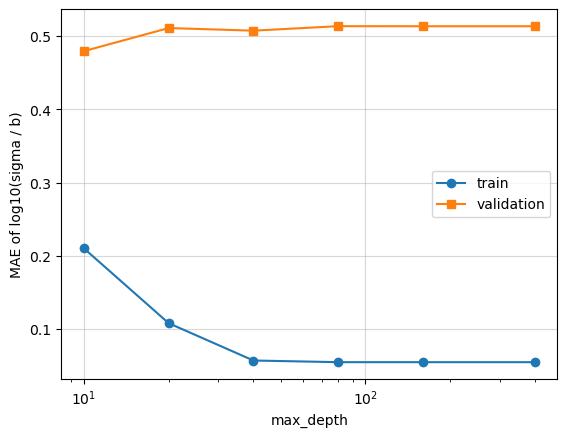

In [102]:
## SWEEPING MAX_DEPTH

results = []

def run(label, max_depth, mss=2, msl=2, X=None, y=None):
    "We fit one tree with the settings detailed in the paper, then log train/val MAE (log10 sigma)"

    X = X_train if X is None else X
    y = y_train if y is None else y
    m = DecisionTreeRegressor(
        criterion = "squared_error",
        splitter = "best",
        max_depth = max_depth,
        min_samples_split = mss,
        min_samples_leaf = msl,
        random_state = 0
    )

    t0 = time.perf_counter()
    m.fit(X,y)
    secs = time.perf_counter() - t0
    row = dict(label=label, max_depth = max_depth, mss = mss, msl = msl,
        train_mae = mean_absolute_error(y, m.predict(X)),
        val_mae = mean_absolute_error(y_val, m.predict(X_val)),
        actual_depth = m.get_depth(), leaves = m.get_n_leaves(), secs = secs)
    results.append(row)
    print(f"{label:22s} train MAE ={row['train_mae']:.4f} val MAE={row['val_mae']:.4f} "
          f"depth={row['actual_depth']} leaves={row['leaves']:,} ({secs:.0f}s)")
    return m


for d in [10, 20, 40, 80, 160, 400]:
    run(f"depth={d}", max_depth=d)

s1 = pd.DataFrame(results)
plt.plot(s1["max_depth"], s1["train_mae"], "o-", label="train")
plt.plot(s1["max_depth"], s1["val_mae"], "s-", label="validation")
plt.xscale("log"); plt.xlabel("max_depth"); plt.ylabel("MAE of log10(sigma / b)")
plt.legend(); plt.grid(alpha=0.5) ; plt.show()

In [103]:
## Sweeping min_samples_leaf

best_depth = 10    ## Best validation score

for s in [2, 5, 10, 15]:
    run(f"MSS={s} (MSL=2)", best_depth, mss=s, msl=2)

for l in [2, 5, 10, 15]:
    run(f"MSL={l} (MSS=2)", best_depth, mss=2, msl=l)

MSS=2 (MSL=2)          train MAE =0.2101 val MAE=0.4798 depth=10 leaves=970 (6s)
MSS=5 (MSL=2)          train MAE =0.2101 val MAE=0.4797 depth=10 leaves=963 (6s)
MSS=10 (MSL=2)         train MAE =0.2101 val MAE=0.4515 depth=10 leaves=937 (6s)
MSS=15 (MSL=2)         train MAE =0.2101 val MAE=0.5000 depth=10 leaves=919 (6s)
MSL=2 (MSS=2)          train MAE =0.2101 val MAE=0.4798 depth=10 leaves=970 (6s)
MSL=5 (MSS=2)          train MAE =0.2101 val MAE=0.4354 depth=10 leaves=946 (6s)
MSL=10 (MSS=2)         train MAE =0.2101 val MAE=0.4310 depth=10 leaves=906 (6s)
MSL=15 (MSS=2)         train MAE =0.2101 val MAE=0.4821 depth=10 leaves=880 (7s)


In [ ]:
run("paper: val-based",   70, mss=10, msl=7)
run("paper: hand-picked", 80, mss=15, msl=3)

res = pd.DataFrame(results).sort_values("val_mae")
display(res[["label", "max_depth", "mss", "msl", "train_mae", "val_mae", "secs"]])  

paper: val-based       train MAE =0.0799 val MAE=0.4642 depth=70 leaves=272,290 (10s)
paper: hand-picked     train MAE =0.0649 val MAE=0.5209 depth=80 leaves=658,264 (11s)


,label,max_depth,mss,msl,train_mae,val_mae,secs
12,MSL=10 (MSS=2),10,2,10,0.210110,0.431037,6.131471
11,MSL=5 (MSS=2),10,2,5,0.210079,0.435356,6.465075
14,paper: val-based,70,10,7,0.079872,0.464246,10.142786
0,depth=10,10,2,2,0.210095,0.479781,6.006134
6,MSS=2 (MSL=2),10,2,2,0.210095,0.479781,6.006080
7,MSS=5 (MSL=2),10,5,2,0.210095,0.479781,6.061774
8,MSS=10 (MSL=2),10,10,2,0.210095,0.479781,6.171891
9,MSS=15 (MSL=2),10,15,2,0.210095,0.479781,6.026725
10,MSL=2 (MSS=2),10,2,2,0.210095,0.479781,6.173172
13,MSL=15 (MSS=2),10,2,15,0.210127,0.482135,6.104217


In [39]:
m = run("depth=10 msl=10", 10, msl=10)

err = (pd.Series(m.predict(X_val), index=y_val.index) - y_val).abs()
by_iso = err.groupby(validation["iso"]).agg(mae="mean", rows="size")
by_iso["share"] = by_iso["rows"] / len(validation)
display(by_iso.sort_values("rows", ascending=False).head(10))
print("Isotopes in validation:", validation["iso"].nunique())

depth=10 msl=10        train MAE =0.2101 val MAE=0.4310 depth=10 leaves=906 (6s)


,mae,rows,share
iso,,,
93237,0.506498,121051,0.293112
27059,0.309756,57753,0.139843
95241,0.591503,43870,0.106226
11023,0.380211,30939,0.074915
83209,0.280363,29205,0.070717
21045,0.313521,21322,0.051629
29065,0.284882,20706,0.050137
97249,0.725942,13778,0.033362
45103,0.288475,13051,0.031602


Isotopes in validation: 36


In [41]:
## Shallower?

for d in [3, 4, 5, 6, 8, 10, 12, 15]:
    run(f"depth={d}", d)

depth=3                train MAE =0.3637 val MAE=0.6240 depth=3 leaves=8 (3s)
depth=4                train MAE =0.3279 val MAE=0.5879 depth=4 leaves=16 (4s)
depth=5                train MAE =0.2994 val MAE=0.5784 depth=5 leaves=32 (4s)
depth=6                train MAE =0.2772 val MAE=0.5156 depth=6 leaves=64 (5s)
depth=8                train MAE =0.2367 val MAE=0.4784 depth=8 leaves=251 (6s)
depth=10               train MAE =0.2101 val MAE=0.4798 depth=10 leaves=970 (6s)
depth=12               train MAE =0.1878 val MAE=0.4675 depth=12 leaves=3,518 (7s)
depth=15               train MAE =0.1546 val MAE=0.4888 depth=15 leaves=19,394 (8s)


In [ ]:
## MSS / MSL only matter a lot for deep trees, so what if we test on a deep tree?

for l in [2, 3, 5, 7, 10, 15]:
    run(f"deep, MSL={l}", 400, mss=2, msl=l)
for s in [2, 5, 10, 15]:
    run(f"deep, MSS={s}", 400, mss=s, msl=2)

deep, MSL=2            train MAE =0.0545 val MAE=0.5138 depth=101 leaves=1,009,385 (11s)
deep, MSL=3            train MAE =0.0649 val MAE=0.5209 depth=83 leaves=658,271 (11s)
deep, MSL=5            train MAE =0.0745 val MAE=0.5230 depth=78 leaves=383,340 (11s)
deep, MSL=7            train MAE =0.0799 val MAE=0.4644 depth=78 leaves=272,392 (10s)
deep, MSL=10           train MAE =0.0853 val MAE=0.4662 depth=76 leaves=189,829 (10s)
deep, MSL=15           train MAE =0.0918 val MAE=0.4655 depth=76 leaves=126,202 (10s)
deep, MSS=2            train MAE =0.0545 val MAE=0.5138 depth=101 leaves=1,009,385 (13s)
deep, MSS=5            train MAE =0.0545 val MAE=0.5138 depth=101 leaves=1,009,385 (13s)
deep, MSS=10           train MAE =0.0545 val MAE=0.5138 depth=101 leaves=1,009,385 (14s)
deep, MSS=15           train MAE =0.0545 val MAE=0.5138 depth=101 leaves=1,009,385 (13s)


In [43]:
print("row-weighted MAE:    ", err.mean())
print("isotope-averaged MAE:", by_iso["mae"].mean())
print("median isotope MAE:  ", by_iso["mae"].median())
print("Isotopes in validation:", validation["iso"].nunique())

np237 = validation["iso"] == 93237
display(err[np237].groupby(validation.loc[np237, "MT"])
        .agg(mae="mean", rows="size")
        .sort_values("rows", ascending=False).head(8))

row-weighted MAE:     0.4310371751189725
isotope-averaged MAE: 0.5902504985521184
median isotope MAE:   0.31412887360070374
Isotopes in validation: 36


,mae,rows
MT,,
1,0.274072,36842
18,0.894944,34727
102,0.326649,28509
9000,0.517336,20800
2,0.342282,168
16,0.608822,2
101,0.543750,2
103,3.175270,1


Best MAE seems to be 0.4310 with the following settings:

- max_depth = 10
- min_samples_leaf = 10
- min_samples_split = 2

In [79]:
### Optimised tree training:

dt = DecisionTreeRegressor(criterion="squared_error", splitter = "best", max_depth=76, min_samples_leaf=15, min_samples_split=2, random_state=0)

dt.fit(X_train, y_train)

## Experimental measurements..

exp = cl_np.copy()

In [80]:
display(libraries.available())

curves = libraries.curve(target = "Cl-35", mt=103)

print(curves["library"].unique())

,file,form,library,points,e_min_eV,e_max_eV
0,Au197_ng.csv,pointwise,ENDF-B-VIII.0,5242,1.000000e-05,20000000.0
1,Au197_ng_bins.csv,bin averages,ENDF-B-VII.1,50,1.000000e-05,20000000.0
2,Au197_ng_bins.csv,bin averages,ENDF-B-VIII.0,50,1.000000e-05,20000000.0
3,Au197_ng_bins.csv,bin averages,JENDL-5,50,1.000000e-05,20000000.0
4,Cl35_np.csv,pointwise,ENDF-B-VII.1,15483,1.000000e+05,20000000.0
...,...,...,...,...,...,...
83,Zr90_n2n.csv,pointwise,ENDF-B-VIII.0,13,1.210429e+07,20000000.0
84,Zr90_n2n.csv,pointwise,JENDL-5,19,1.210280e+07,20000000.0
85,Zr90_n2n_bins.csv,bin averages,ENDF-B-VII.1,2,1.000000e+07,20000000.0
86,Zr90_n2n_bins.csv,bin averages,ENDF-B-VIII.0,2,1.000000e+07,20000000.0


['ENDF-B-VII.1' 'ENDF-B-VIII.0' 'JENDL-5']


In [96]:
## Want the newer data back..


original_table["entry_date"] = pd.to_datetime(
    original_table["entry_date"].astype(str),
    errors="coerce"
)

new_data = original_table[
    (original_table["author"].str.contains("Batchelder", case=False, na=False))         ## Filters out by "Batchelder" and after "23/04/2021"
].copy()


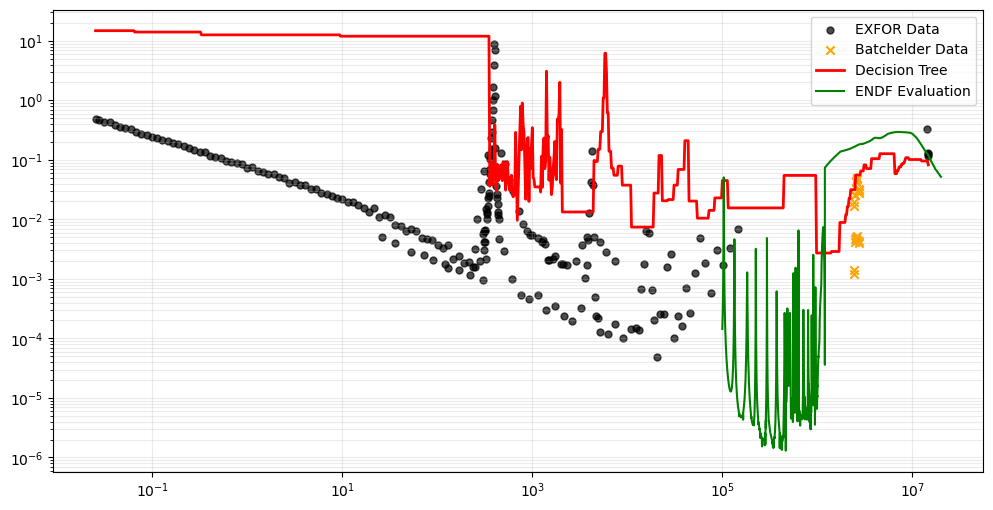

In [101]:
## Evaluations

endf_old = libraries.curve("Cl-35", 103, "ENDF-B-VII.1")
endf_new = libraries.curve("Cl-35", 103, "ENDF-B-VIII.0")
jendl = libraries.curve("Cl-35", 103, "JENDL-5")                ## This one isn't actually used in the paper, only ENDF

energy_grid = np.logspace(
    np.log10(cl_np["energy_eV"].min()),
    np.log10(cl_np["energy_eV"].max()),
    1000
)

grid = pd.concat(
    [cl_np.iloc[[0]]] * len(energy_grid),
    ignore_index=True
)

grid["energy_eV"] = energy_grid
grid["sigma_b"] = 1.0

X_grid, _ = make_xy(grid, X_train.columns)

y_pred_log = dt.predict(X_grid)
y_pred = 10**y_pred_log



## Plotting

plt.figure(figsize=(12,6))

plt.scatter(cl_np["energy_eV"], cl_np["sigma_b"], color="black", s=25, alpha=0.7, label= "EXFOR Data")
plt.scatter(new_data["energy_eV"], new_data["sigma_b"], marker="x", color='orange', label="Batchelder Data")

plt.plot(energy_grid, y_pred, color='red', linewidth = 2, label= "Decision Tree")

plt.plot(endf_new["energy_eV"], endf_new["sigma_b"], color='green', label = "ENDF Evaluation")

plt.xscale("log") ; plt.yscale("log")
plt.grid(which = "both", alpha=0.25)
plt.legend()
plt.show()

this is just terrible, also why is the ENDF evaluation not in the right energy range?